# D4 · 对照评估 / LIANG SHUANG

**2026-10-16 更新：C 正式管线已接入并完成本机验证；B 的发现、人工复核和最终测试待完成。**

依据 A 的固定数据契约和用户提供的 C_Pipeline(1).zip，D 负责统一评价。本次内嵌的是 C 原始正式实现，不再使用 D 的临时管线。C 源码原字节保持不变；原包证据与本机复跑证据分开保存，旧 D 结果保存在 outputs/D/history/reference_20261015。analysis.ipynb 是 A+C+D 整合草稿，B 部分仍明确留空。

## 1. Protocol and provenance

Same 11 raw features, frozen A splits, same logistic regression (C=1, lbfgs, max_iter=2000, class_weight=None), threshold p>=0.5. E0=(S off,U off), ES=(on,off), EU=(off,on), ESU=(on,on). Validation fits train only; final test refits train+val after B/C review. No hyperparameter/threshold search. Age and original unknown groups were specified by the manual before evaluation. All core loading, transformation and metric functions are included below for C to merge.

In [1]:
from pathlib import Path
import sys, json, platform
ROOT = Path.cwd()
if not (ROOT / 'data/raw/bank-full.csv').exists():
    ROOT = ROOT.parent
assert (ROOT / 'data/raw/bank-full.csv').exists(), 'Run from repository root or notebooks/'
import sklearn, pandas as pd, numpy as np
print({'python': platform.python_version(), 'sklearn': sklearn.__version__, 'pandas': pd.__version__, 'numpy': np.__version__})

{'python': '3.12.14', 'sklearn': '1.8.0', 'pandas': '3.0.6', 'numpy': '2.5.4'}


## 2. Frozen A loading contract (included source)

row_id is a tracking index, never a predictor. Test loader is guarded; the validation cells below never request test. Hash/format checks on the raw source are part of A’s existing integrity contract, not exploratory test analysis.

In [2]:
"""Frozen data contract shared by A/B/C/D. No learned transformations."""

import hashlib
import json
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

LOCK = json.loads((ROOT / "config/dataset_lock.json").read_text(encoding="utf-8"))
EXPECTED_COLUMNS = LOCK["columns"]
FEATURES = LOCK["allowed_features"]
EXCLUDED = LOCK["excluded_features"]
NUMERIC = ["age", "balance", "day", "duration", "campaign", "pdays", "previous"]
CATEGORIES = {
    "job": ["admin.", "unknown", "unemployed", "management", "housemaid", "entrepreneur", "student", "blue-collar", "self-employed", "retired", "technician", "services"],
    "marital": ["married", "divorced", "single"],
    "education": ["unknown", "secondary", "primary", "tertiary"],
    "default": ["yes", "no"], "housing": ["yes", "no"], "loan": ["yes", "no"],
    "contact": ["unknown", "telephone", "cellular"],
    "month": ["jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"],
    "poutcome": ["unknown", "other", "failure", "success"], "y": ["yes", "no"],
}


def sha256_bytes(data: bytes) -> str:
    return hashlib.sha256(data).hexdigest()


def verify_bytes(data: bytes, expected: dict, label: str) -> None:
    if sha256_bytes(data) != expected["sha256"]:
        raise ValueError(f"SHA-256 mismatch: {label}. Do not repair or overwrite the raw file.")
    if "bytes" in expected and len(data) != expected["bytes"]:
        raise ValueError(f"Byte length mismatch: {label}")


def read_raw(root: Path = ROOT) -> pd.DataFrame:
    path = root / "data/raw/bank-full.csv"
    verify_bytes(path.read_bytes(), LOCK["artifacts"]["data/raw/bank-full.csv"], str(path.name))
    raw = pd.read_csv(path, sep=";", keep_default_na=False)
    if list(raw.columns) != EXPECTED_COLUMNS or raw.shape != (45211, 17):
        raise ValueError("Unexpected CSV version, columns, or shape")
    for column in NUMERIC:
        if not pd.api.types.is_integer_dtype(raw[column]):
            raise ValueError(f"Expected integer dtype: {column}")
    for column, allowed in CATEGORIES.items():
        if not raw[column].isin(allowed).all():
            raise ValueError(f"Unexpected category: {column}")
    if raw.isna().any().any() or raw.astype(str).apply(lambda s: s.str.strip().eq("")).any().any():
        raise ValueError("Unexpected actual missing/empty cell")
    raw.index.name = "row_id"  # Original zero-based data-record position, not CSV line number.
    return raw


def make_splits(raw: pd.DataFrame) -> dict[str, np.ndarray]:
    y = raw["y"].map({"no": 0, "yes": 1})
    if y.isna().any():
        raise ValueError("Unexpected target value")
    ids = np.arange(len(raw))
    dev, test = train_test_split(ids, test_size=.20, stratify=y, random_state=42)
    train, val = train_test_split(dev, test_size=.25, stratify=y.iloc[dev], random_state=42)
    return {"train": train, "val": val, "test": test}


def make_manifest(raw: pd.DataFrame, splits: dict[str, np.ndarray]) -> pd.DataFrame:
    assignment = pd.Series("", index=np.arange(len(raw)), name="split")
    for name, ids in splits.items():
        assignment.loc[ids] = name
    result = assignment.rename_axis("row_id").reset_index()
    all_ids = np.concatenate(list(splits.values()))
    if len(all_ids) != len(raw) or len(np.unique(all_ids)) != len(raw):
        raise ValueError("Splits overlap or fail complete coverage")
    if not np.array_equal(np.sort(all_ids), np.arange(len(raw))) or assignment.eq("").any():
        raise ValueError("Invalid split row ids")
    return result


def load_split_indices(root: Path = ROOT) -> dict[str, np.ndarray]:
    saved = json.loads((root / "data/splits/split_indices.json").read_text(encoding="utf-8"))
    if not isinstance(saved, dict) or set(saved) != {"train", "val", "test"}:
        raise ValueError("Unexpected split names")
    for name, ids in saved.items():
        if not isinstance(ids, list) or any(type(value) is not int for value in ids):
            raise ValueError(f"Split {name} row ids must be plain JSON integers; no strings, floats or booleans")
        if any(value < 0 or value >= LOCK["shape"][0] for value in ids):
            raise ValueError(f"Split {name} row id outside original row range")
    return {name: np.asarray(ids, dtype=np.int64) for name, ids in saved.items()}


def validate_saved_splits(raw: pd.DataFrame, root: Path = ROOT) -> dict[str, np.ndarray]:
    expected = make_splits(raw)
    saved = load_split_indices(root)
    for name in expected:
        if not np.array_equal(saved[name], expected[name]):
            raise ValueError(f"Frozen split changed: {name}")
    manifest = pd.read_csv(root / "data/splits/split_manifest.csv", keep_default_na=False)
    pd.testing.assert_frame_equal(manifest, make_manifest(raw, expected))
    return saved


def load_partition(name: str, *, allow_test: bool = False, root: Path = ROOT):
    """Return X (11 original columns), integer y, with aligned row_id indices.

    The flag is a workflow guard, not access control: raw data remain available.
    C/D must preserve this row order and fit learned transforms only on training.
    """
    if name not in {"train", "val", "test"}:
        raise ValueError("Expected train, val, or test")
    if name == "test" and not allow_test:
        raise ValueError("Test is sealed until protocol freeze; D must explicitly allow_test=True")
    raw = read_raw(root)
    splits = validate_saved_splits(raw, root)
    frame = raw.loc[splits[name]]
    X = frame.loc[:, FEATURES].copy()
    y = frame["y"].map({"no": 0, "yes": 1}).astype("int64")
    if not X.index.equals(y.index) or list(X.columns) != FEATURES:
        raise ValueError("Broken model-input contract")
    return X, y


## 3. C formal pipeline / received and locally rerun

C code source is src/preprocessing.py. S separates the contact flag and conditional interval; the binary flag remains unscaled. U affects only job/education. Genuine missing values, invalid pdays and all-unknown mode-fit columns are rejected. C splits job/education from the remaining categorical block, so feature order differs from the historical D reference. Use its feature names to align coefficients. Both representations match exactly after canonical name alignment; see outputs/C/migration_comparison.csv. The current runs all use requirements.D.lock.txt, not a mixture of C and D environments.

In [3]:
"""C / D3：手册第 6 页的正式 S/U 管线；不读取任何分区。"""

import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.utils.validation import check_is_fitted


# FEATURES defined in the included A contract above

EXPERIMENTS = {"E0": (False, False), "ES": (True, False),
               "EU": (False, True), "ESU": (True, True)}
CATEGORICAL = ["job", "marital", "education", "default", "housing", "loan", "poutcome"]


class SemanticTransformer(TransformerMixin, BaseEstimator):
    """白名单、原始异常检查和不学习参数的语义转换；保留 index。"""

    def __init__(self, use_s=False, use_u=False):
        self.use_s = use_s
        self.use_u = use_u

    def _prepare(self, X):
        if not isinstance(X, pd.DataFrame):
            raise TypeError("Expected a pandas DataFrame with named raw columns")
        if X.columns.duplicated().any() or not set(FEATURES).issubset(X.columns):
            raise ValueError("Missing or duplicate input columns")
        frame = X.loc[:, FEATURES].copy(deep=True)
        # 真空值属于上游 STOP；U 产生的 NaN 在此检查之后出现。
        if frame.isna().any().any():
            raise ValueError("STOP: actual missing values; ask A to verify raw data")
        for name in ["age", "balance", "pdays", "previous"]:
            if not pd.api.types.is_numeric_dtype(frame[name]) or not np.isfinite(frame[name]).all():
                raise ValueError(f"STOP: invalid numeric column {name}")
        if (frame.pdays < -1).any() or (frame.pdays % 1 != 0).any():
            raise ValueError("STOP: invalid pdays; expected -1 or nonnegative integer days")
        for name in CATEGORICAL:
            if not frame[name].map(lambda v: isinstance(v, str) and bool(v.strip())).all():
                raise ValueError(f"STOP: invalid category in {name}")
        if self.use_s:
            frame["has_previous_contact"] = (frame.pdays >= 0).astype("int64")
            frame["days_since_previous"] = frame.pdays.where(frame.pdays >= 0, 0)
            frame = frame.drop(columns="pdays")
        if not self.use_u:
            for name in ["job", "education"]:
                frame[name] = frame[name].astype(object).replace("unknown", np.nan)
        return frame

    def fit(self, X, y=None):
        frame = self._prepare(X)
        if not self.use_u and frame[["job", "education"]].isna().all().any():
            raise ValueError("STOP: no observed job/education mode in fit data")
        self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        self.n_features_in_ = X.shape[1]
        self.feature_names_out_ = np.asarray(frame.columns, dtype=object)
        return self

    def transform(self, X):
        check_is_fitted(self, "feature_names_out_")
        return self._prepare(X)

    def get_feature_names_out(self, input_features=None):
        check_is_fitted(self, "feature_names_out_")
        return self.feature_names_out_.copy()


class MarketingPipeline(Pipeline):
    """完整分类器也提供编码特征名；标准 Pipeline 的末端模型无此接口。"""

    def get_feature_names_out(self, input_features=None):
        steps = self.steps[:-1] if self.steps and self.steps[-1][0] == 'model' else self.steps
        return Pipeline(steps).get_feature_names_out(input_features)


def build_pipeline(use_s: bool, use_u: bool):
    """每次返回未拟合的新对象，供 D 在当前 fit 分区独立训练。"""
    if type(use_s) is not bool or type(use_u) is not bool:
        raise TypeError("use_s and use_u must be bool")
    numeric = ["age", "balance", "previous", "days_since_previous" if use_s else "pdays"]
    numeric_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])
    unknown_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", drop=None)),
    ])
    other_categories = [x for x in CATEGORICAL if x not in ["job", "education"]]
    transformers = [
        ("numeric", numeric_pipe, numeric),
        ("job_education", OneHotEncoder(handle_unknown="ignore", drop=None) if use_u else unknown_pipe,
         ["job", "education"]),
        ("categorical", OneHotEncoder(handle_unknown="ignore", drop=None), other_categories),
    ]
    if use_s:
        transformers.append(("status", "passthrough", ["has_previous_contact"]))
    return MarketingPipeline([
        ("semantic", SemanticTransformer(use_s=use_s, use_u=use_u)),
        ("preprocess", ColumnTransformer(transformers, remainder="drop")),
        ("model", LogisticRegression(C=1.0, solver="lbfgs", max_iter=2000,
                                     class_weight=None, random_state=42)),
    ])


## 4. Unified metrics and original groups

AP is average precision, not trapezoidal PR-AUC. Brier=mean((p-y)^2). Recall=TP/(TP+FN), FPR=FP/(FP+TN), F1=2TP/(2TP+FP+FN). NaN means undefined denominator; AP is undefined without positives. Small sample: n<100 or positives<20 or negatives<20. Brier and FPR are lower-is-better. Recall changes multiplied by 100 are percentage points.

In [4]:
"""Shared evaluation, no model selection or holdout-dependent choices."""
import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score

EXPERIMENTS = {'E0': (False, False), 'ES': (True, False),
               'EU': (False, True), 'ESU': (True, True)}
THRESHOLD = 0.5
METRICS = ['AP', 'Recall', 'F1', 'Brier', 'Accuracy', 'FPR']
CONTRASTS = [('S_Uoff', 'ES', 'E0'), ('S_Uon', 'ESU', 'EU'),
             ('U_Soff', 'EU', 'E0'), ('U_Son', 'ESU', 'ES'),
             ('full', 'ESU', 'E0')]


def ratio(numerator, denominator):
    return float(numerator / denominator) if denominator else float('nan')


def evaluate(y, probability):
    y = np.asarray(y)
    p = np.asarray(probability, dtype=float)
    if y.ndim != 1 or p.shape != y.shape or not np.isin(y, [0, 1]).all():
        raise ValueError('Labels/probabilities must be aligned binary 1-D arrays')
    if not np.isfinite(p).all() or ((p < 0) | (p > 1)).any():
        raise ValueError('Non-finite or out-of-range probability')
    pred = p >= THRESHOLD
    tp = int(((y == 1) & pred).sum())
    fp = int(((y == 0) & pred).sum())
    tn = int(((y == 0) & ~pred).sum())
    fn = int(((y == 1) & ~pred).sum())
    n = len(y)
    return dict(n=n, n_positive=tp+fn, n_negative=tn+fp, TP=tp, FP=fp, TN=tn, FN=fn,
                AP=float(average_precision_score(y, p)) if tp+fn else float('nan'),
                Recall=ratio(tp, tp+fn), FPR=ratio(fp, fp+tn),
                Precision=ratio(tp, tp+fp), F1=ratio(2*tp, 2*tp+fp+fn),
                Brier=float(np.mean((p-y)**2)) if n else float('nan'),
                Accuracy=ratio(tp+tn, n), threshold=THRESHOLD)


def group_labels(X):
    # Raw pre-imputation information status, never recomputed from encoded features.
    age = pd.Series(np.where(X.age < 30, '<30', np.where(X.age < 60, '30-59', '>=60')), index=X.index)
    missing = X[['job', 'education']].eq('unknown').any(axis=1)
    return {'age': age, 'information': pd.Series(np.where(missing, 'any_unknown', 'both_known'), index=X.index)}


def subgroup_metrics(X, y, p, experiment):
    rows = []
    for dimension, labels in group_labels(X).items():
        levels = ['<30', '30-59', '>=60'] if dimension == 'age' else ['any_unknown', 'both_known']
        for label in levels:
            mask = labels.eq(label).to_numpy()
            row = evaluate(np.asarray(y)[mask], np.asarray(p)[mask])
            row.update(experiment=experiment, dimension=dimension, group=label,
                       small_sample=bool(row['n'] < 100 or row['n_positive'] < 20 or row['n_negative'] < 20))
            rows.append(row)
    return rows


def contrasts(table, group_columns=()):
    rows = []
    iterator = table.groupby(list(group_columns), sort=False) if group_columns else [((), table)]
    for keys, frame in iterator:
        keys = keys if isinstance(keys, tuple) else (keys,)
        indexed = frame.set_index('experiment')
        for effect, after, before in CONTRASTS:
            row = dict(zip(group_columns, keys))
            row.update(effect=effect, contrast=after+'-'+before)
            for metric in METRICS:
                row['delta_'+metric] = indexed.loc[after, metric] - indexed.loc[before, metric]
            if group_columns:
                row['n'] = int(indexed.loc[after, 'n'])
                row['small_sample'] = bool(indexed.loc[after, 'small_sample'])
            rows.append(row)
    return pd.DataFrame(rows)


## 5. Reproduce all four validation experiments

Only the 60% train partition is fitted. Each probability retains the exact frozen validation row_id order. Training contains 27,126 rows / 3,173 positives; validation contains 9,042 rows / 1,058 positives.

In [5]:
import warnings
from sklearn.exceptions import ConvergenceWarning
X_train, y_train = load_partition('train')
X_val, y_val = load_partition('val')
rows, group_rows, probability_frames, fitted = [], [], [], {}
for experiment, (s,u) in EXPERIMENTS.items():
    pipe = build_pipeline(s,u)
    with warnings.catch_warnings():
        warnings.simplefilter('error', ConvergenceWarning)
        pipe.fit(X_train, y_train)
    probability = pipe.predict_proba(X_val)[:,1]
    rows.append(dict(experiment=experiment, **evaluate(y_val, probability)))
    group_rows.extend(subgroup_metrics(X_val,y_val,probability,experiment))
    probability_frames.append(pd.DataFrame({'row_id':X_val.index,'experiment':experiment,'y_true':y_val.to_numpy(),'probability':probability}))
    fitted[experiment] = pipe
validation = pd.DataFrame(rows)
subgroups = pd.DataFrame(group_rows)
probabilities = pd.concat(probability_frames, ignore_index=True)
expected = pd.read_csv(ROOT/'outputs/D/validation/metrics.csv')
np.testing.assert_allclose(validation[METRICS], expected[METRICS], rtol=1e-10, atol=1e-12)
display(validation[['experiment','n','n_positive','AP','Recall','F1','Brier','Accuracy','TP','FP','TN','FN']])


,experiment,n,n_positive,AP,Recall,F1,Brier,Accuracy,TP,FP,TN,FN
0,E0,9042,1058,0.358497,0.172968,0.277273,0.089328,0.894492,183,79,7905,875
1,ES,9042,1058,0.359485,0.172968,0.277273,0.089325,0.894492,183,79,7905,875
2,EU,9042,1058,0.358526,0.171078,0.274659,0.089337,0.894271,181,79,7905,877
3,ESU,9042,1058,0.359403,0.172023,0.275967,0.089333,0.894382,182,79,7905,876


## 6. References and all five contrasts

All-no accuracy is 88.299%, so roughly 89.4% model accuracy should not hide low positive recall. The constant training-prior probability is an extra no-feature probability reference.

In [6]:
reference_rows=[]
for label,p in [('all_no',0.),('training_prior',float(y_train.mean()))]:
    reference_rows.append(dict(reference=label, **evaluate(y_val,np.full(len(y_val),p))))
display(pd.DataFrame(reference_rows))
display(contrasts(validation))

,reference,n,n_positive,n_negative,TP,FP,TN,FN,AP,Recall,FPR,Precision,F1,Brier,Accuracy,threshold
0,all_no,9042,1058,7984,0,0,7984,1058,0.11701,0.0,0.0,NaN,0.0,0.117010,0.88299,0.5
1,training_prior,9042,1058,7984,0,0,7984,1058,0.11701,0.0,0.0,NaN,0.0,0.103318,0.88299,0.5


,effect,contrast,delta_AP,delta_Recall,delta_F1,delta_Brier,delta_Accuracy,delta_FPR
0,S_Uoff,ES-E0,0.000987,0.000000,0.000000,-0.000003,0.000000,0.0
1,S_Uon,ESU-EU,0.000877,0.000945,0.001308,-0.000005,0.000111,0.0
2,U_Soff,EU-E0,0.000028,-0.001890,-0.002614,0.000009,-0.000221,0.0
3,U_Son,ESU-ES,-0.000082,-0.000945,-0.001306,0.000007,-0.000111,0.0
4,full,ESU-E0,0.000905,-0.000945,-0.001306,0.000005,-0.000111,0.0


## 7. Subgroup audit

Information groups use original job/education values. Each dimension partitions validation independently. Rows from age and information dimensions overlap and must not be added together.

In [7]:
display(subgroups[['experiment','dimension','group','n','n_positive','n_negative','TP','FP','TN','FN','Recall','FPR','Brier','small_sample']])
group_deltas=contrasts(subgroups,['dimension','group'])
display(group_deltas[group_deltas.effect.eq('full')])

,experiment,dimension,group,n,n_positive,n_negative,TP,FP,TN,FN,Recall,FPR,Brier,small_sample
0,E0,age,<30,1075,196,879,34,17,862,162,0.173469,0.019340,0.131222,False
1,E0,age,30-59,7603,734,6869,120,50,6819,614,0.163488,0.007279,0.076871,False
2,E0,age,>=60,364,128,236,29,12,224,99,0.226562,0.050847,0.225793,False
3,E0,information,any_unknown,407,46,361,10,6,355,36,0.217391,0.016620,0.083210,False
4,E0,information,both_known,8635,1012,7623,173,73,7550,839,0.170949,0.009576,0.089616,False
5,ES,age,<30,1075,196,879,34,17,862,162,0.173469,0.019340,0.131258,False
6,ES,age,30-59,7603,734,6869,120,50,6819,614,0.163488,0.007279,0.076858,False
7,ES,age,>=60,364,128,236,29,12,224,99,0.226562,0.050847,0.225897,False
8,ES,information,any_unknown,407,46,361,10,6,355,36,0.217391,0.016620,0.083222,False
9,ES,information,both_known,8635,1012,7623,173,73,7550,839,0.170949,0.009576,0.089613,False


,dimension,group,effect,contrast,delta_AP,delta_Recall,delta_F1,delta_Brier,delta_Accuracy,delta_FPR,n,small_sample
4,age,<30,full,ESU-E0,0.001520,0.000000,0.000000,-6.234996e-06,0.000000,0.0,1075,False
9,age,30-59,full,ESU-E0,0.001622,0.000000,0.000000,-7.425374e-07,0.000000,0.0,7603,False
14,age,>=60,full,ESU-E0,-0.001322,-0.007812,-0.009862,1.493454e-04,-0.002747,0.0,364,False
19,information,any_unknown,full,ESU-E0,0.001488,0.000000,0.000000,1.229313e-04,0.000000,0.0,407,False
24,information,both_known,full,ESU-E0,0.000712,-0.000988,-0.001372,-9.287144e-07,-0.000116,0.0,8635,False


## 8. Evidence charts (generated from reproduced values)

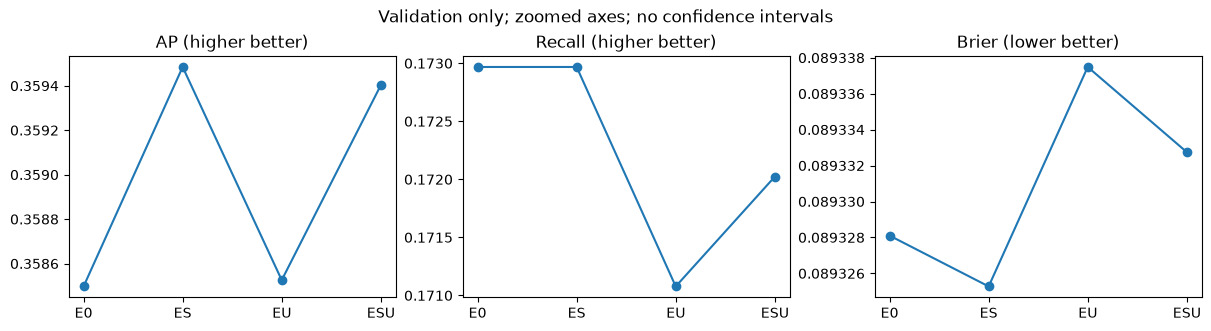

In [8]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1,3,figsize=(12,3.2),layout='constrained')
for ax,metric in zip(axes,['AP','Recall','Brier']):
    ax.plot(validation.experiment,validation[metric],marker='o')
    ax.set_title(metric+(' (lower better)' if metric=='Brier' else ' (higher better)'))
    ax.ticklabel_format(axis='y',style='plain',useOffset=False)
fig.suptitle('Validation only; zoomed axes; no confidence intervals')
plt.show()


## 9. Interpretation and limits

S increases overall AP by about 0.00099 (U off) or 0.00088 (U on), with very small Brier changes. U has mixed AP effects and slightly worse Brier under both S settings. ESU-E0: AP +0.000905, Recall -0.0945 percentage points, F1 -0.001306, Brier +0.00000465. These are small descriptive changes, with no significance claim.

At age>=60, ESU identifies 28/128 positives vs E0’s 29/128: recall drops 0.78125 percentage points. Unknown-information Brier worsens by 0.00012293 while recall stays 10/46. Overall AP can improve while some groups incur a cost. None of the displayed validation groups triggers the manual’s small-sample warning, which does not establish statistical precision.

Possible redundancy with previous/poutcome awaits B’s train-only evidence. S changes representation, feature count and regularization geometry. Brier is not a stand-alone calibration test. No causal, discrimination, customer-independent, time-generalization or financial-return claim. Retaining unknown does not automatically improve performance. A semantics improvement can remain defensible even if scores barely change.

## 10. Final-test status and handoff

**Not executed.** C source and tests have been received and locally verified. B’s training-only discovery tables and group/interpretation confirmation are still absent. Human review is pending. See notes/D_MISSING_ITEMS.md. After receiving and reviewing the missing evidence, fill the real handoff receipt, freeze, then run scripts/run_d.py test once. Final fits must use 36,168 train+val rows; test contains 9,043 rows. Do not copy validation scores into test columns. All four test settings and all planned contrasts must be reported.

In [9]:
final_test_status = {'test_evaluated': False, 'C_code': 'received_and_locally_verified', 'B_discovery': 'not_received', 'human_review': 'pending'}
print(final_test_status)

{'test_evaluated': False, 'C_code': 'received_and_locally_verified', 'B_discovery': 'not_received', 'human_review': 'pending'}


## 11. GenAI and contribution declaration

User identifies LIANG SHUANG as D. A owns the data foundation; C supplied the formal pipeline, tests and C chapter; D owns evaluation and this integration. OpenAI Codex assisted with code review, integration, experiment execution, metric checks, figures and explanation drafts. B’s evidence, actual human understanding/review, the four-person video and course submission remain incomplete. No human review is claimed on anyone’s behalf.

Sources: user-supplied C_Pipeline(1).zip (hash in outputs/C/local_integration.json); local execution manual pp6–10; [A repository](https://github.com/raederhans/ca6003-bank-marketing) commit b4c4ff1be75a6e48baacd920f405982b20399352; [UCI](https://archive.ics.uci.edu/dataset/222/bank+marketing); [AP](https://scikit-learn.org/1.8/modules/generated/sklearn.metrics.average_precision_score.html); [Brier](https://scikit-learn.org/1.8/modules/generated/sklearn.metrics.brier_score_loss.html); [fit boundaries](https://scikit-learn.org/1.8/common_pitfalls.html).